<a href="https://colab.research.google.com/github/muberragul/News-Text-Classification-Classical-ML-vs.-LLMs/blob/main/News-Text-Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#eğer dataset remote bilgisayardaysa
!pip install -U datasets fsspec

#Hugging Face Dataset library
!pip install datasets

from datasets import load_dataset
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 10.0 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
  Attempting uninstall: datasets
    Found existing installation: datasets 2.14.4
    Uninstalling datasets-2.14.4:
      Successfully uninstalled datasets-2.14.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.2 requires fsspec==2025.3.2, but you have fsspec 2025.3.0 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; pl

In [ ]:

ds = load_dataset("fancyzhx/ag_news")

# Pandas Dataframe çevirme, daha kolay analiz için
train_df = ds['train'].to_pandas()
test_df = ds['test'].to_pandas()

# Default HuggingFace sets to CSV
train_df.to_csv("/content/train.csv", index=False)
test_df.to_csv("/content/test.csv", index=False)
print(train_df.shape)
print(test_df.shape)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

(120000, 2)
(7600, 2)


In [ ]:
train_df.head()

,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2




---

**Dataset Analizi**

In [ ]:
train_df.info()
test_df.info()
train_df.isnull().sum()
print("Shape of dataset:", train_df.shape)
print("Columns:", train_df.columns.tolist())
print(train_df.shape)
print(test_df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    120000 non-null  object
 1   label   120000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 1.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7600 entries, 0 to 7599
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    7600 non-null   object
 1   label   7600 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.9+ KB
Shape of dataset: (120000, 2)
Columns: ['text', 'label']
(120000, 2)
(7600, 2)


In [ ]:
train_df.isnull().sum()

,0
text,0
label,0


Train Label Distribution:
label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64

 Test Label Distribution:
label
0    1900
1    1900
2    1900
3    1900
Name: count, dtype: int64


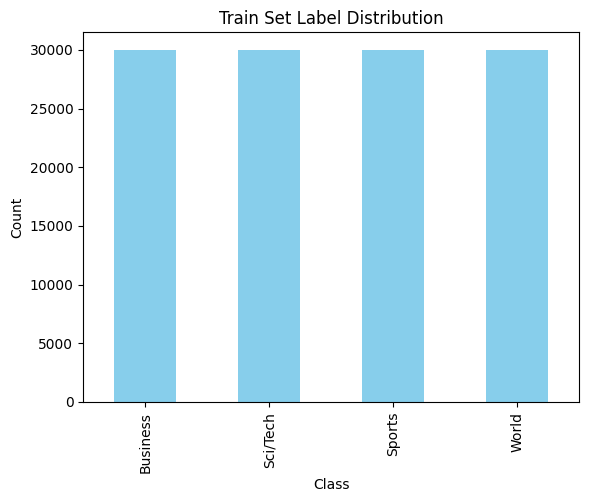

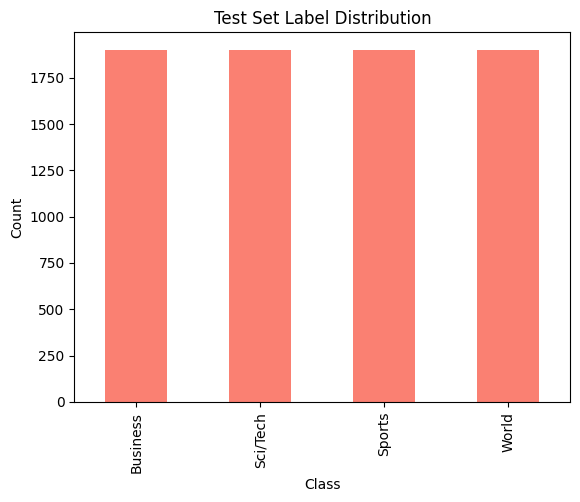

In [ ]:
#balanced bir data set mi?

label_map = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

print("Train Label Distribution:")
print(train_df['label'].value_counts().sort_index())

print("\n Test Label Distribution:")
print(test_df['label'].value_counts().sort_index())

# Label_name sütunu eklenir
train_df["label_name"] = train_df["label"].map(label_map)
test_df["label_name"] = test_df["label"].map(label_map)

# Train set Dağılım Grafiği
train_df['label_name'].value_counts().sort_index().plot(
    kind='bar', title='Train Set Label Distribution', color='skyblue'
)
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Test Set Dağılım Grafiği
test_df['label_name'].value_counts().sort_index().plot(
    kind='bar', title='Test Set Label Distribution', color='salmon'
)
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()



🔠Text Length (Characters) Stats:
count    120000.000000
mean        236.477525
std          66.509741
min         100.000000
25%         196.000000
50%         232.000000
75%         266.000000
max        1012.000000
Name: text_length, dtype: float64

 Word Count Stats:
count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: word_count, dtype: float64


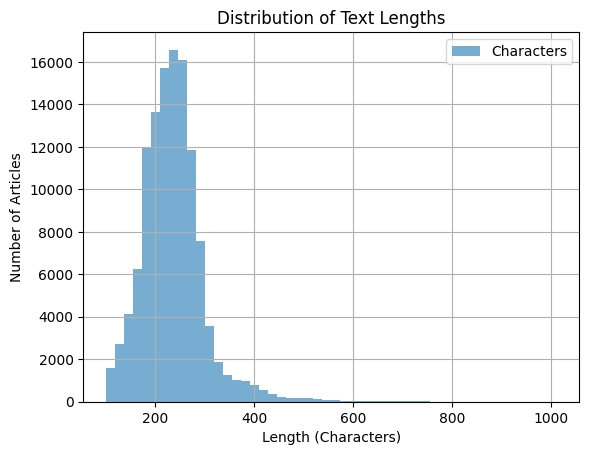

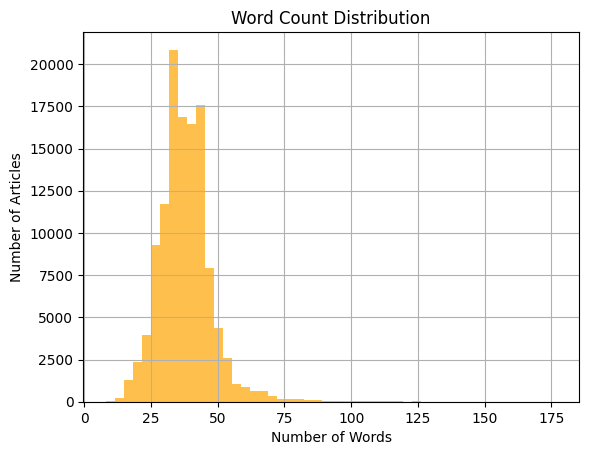

Train Set: (120000, 3)
Test Set: (7600, 3)


In [ ]:
import matplotlib.pyplot as plt

# Metin Uzunluğu ve Kelime Sayısı Analizi

# Karakter ve kelime sayısı sütunları
train_df['text_length'] = train_df['text'].str.len()
train_df['word_count'] = train_df['text'].str.split().str.len()

# İstatistiksel özetler
print("🔠Text Length (Characters) Stats:")
print(train_df['text_length'].describe())

print("\n Word Count Stats:")
print(train_df['word_count'].describe())

# Karakter uzunluğu histogramı
train_df['text_length'].hist(bins=50, alpha=0.6, label='Characters')
plt.xlabel("Length (Characters)")
plt.ylabel("Number of Articles")
plt.title("Distribution of Text Lengths")
plt.legend()
plt.show()

# Kelime sayısı histogramı
train_df['word_count'].hist(bins=50, color='orange', alpha=0.7)
plt.title("Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.show()


# Kullanılmayan sütunları kaldır
train_df.drop(columns=['text_length', 'word_count'], inplace=True)
# (Eğer test_df'e de eklediyseniz)
test_df.drop(columns=['text_length', 'word_count'], inplace=True, errors='ignore')
print("Train Set:", train_df.shape)
print("Test Set:", test_df.shape)



 Dataset Sizes:
Original Train: (120000, 3)
Train Split (90%): (108000, 3)
Validation (10%): (12000, 3)
Test (from HF): (7600, 3)


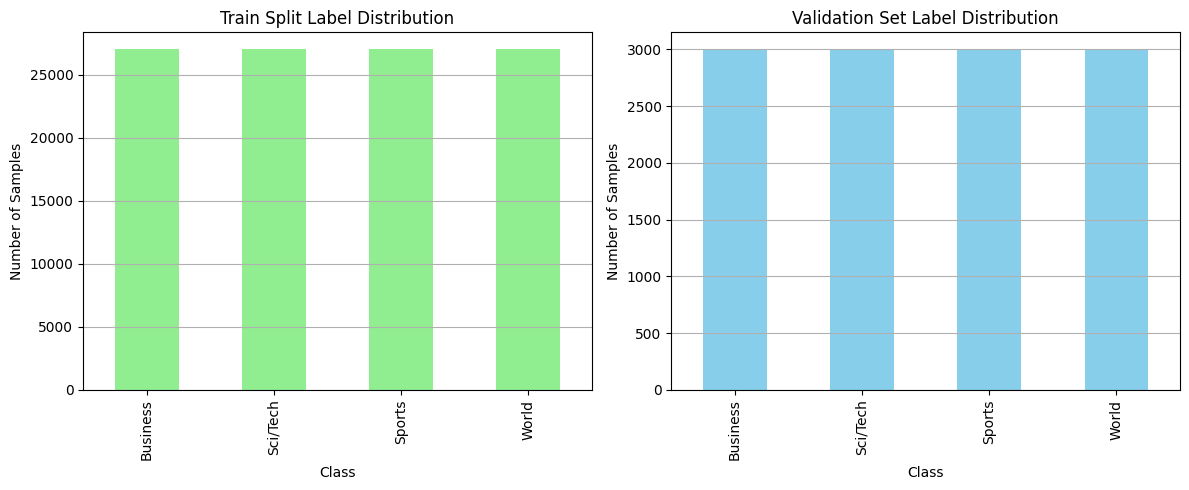

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# %10 validation ayırma (stratified)
label_map = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

train_split_df, val_df = train_test_split(
    train_df,
    test_size=0.1,
    stratify=train_df['label'],
    random_state=42
)

# Label isimlerini ekle
train_split_df["label_name"] = train_split_df["label"].map(label_map)
val_df["label_name"] = val_df["label"].map(label_map)

# CSV olarak kaydet
train_split_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/validation.csv", index=False)

# Veri sayıları ve grafik
print(f" Dataset Sizes:")
print("Original Train:", train_df.shape)
print("Train Split (90%):", train_split_df.shape)
print("Validation (10%):", val_df.shape)
print("Test (from HF):", test_df.shape)

# Karşılaştırmalı dağılım grafiği
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Train split
train_split_df["label_name"].value_counts().sort_index().plot(
    kind='bar', color='lightgreen', ax=axes[0]
)
axes[0].set_title("Train Split Label Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Samples")
axes[0].grid(axis='y')

# Validation set
val_df["label_name"].value_counts().sort_index().plot(
    kind='bar', color='skyblue', ax=axes[1]
)
axes[1].set_title("Validation Set Label Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Samples")
axes[1].grid(axis='y')

plt.tight_layout()
plt.show()


<ipython-input-10-c113df8211c6>:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=4000, random_state=42))
<ipython-input-10-c113df8211c6>:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=1000, random_state=42))


 Train Subsample Label Distribution:
label
0    4000
1    4000
2    4000
3    4000
Name: count, dtype: int64

 Validation Subsample Label Distribution:
label
0    1000
1    1000
2    1000
3    1000
Name: count, dtype: int64


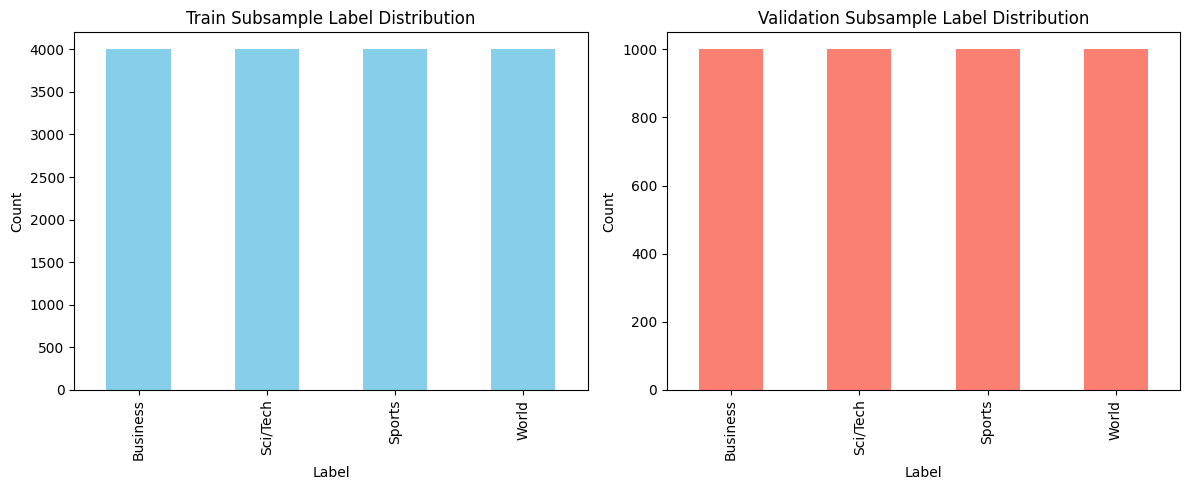

 Shapes after Subsampling:
Train: (16000, 3)
Validation: (4000, 3)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv("/content/train_split.csv")
val_df = pd.read_csv("/content/validation.csv")

# Her sınıftan eşit sayıda örnekle alt kümeler oluştur
train_subsample = (
    train_df.groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=4000, random_state=42))
    .reset_index(drop=True)
)

val_subsample = (
    val_df.groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=1000, random_state=42))
    .reset_index(drop=True)
)

train_subsample.to_csv("/content/train_16k.csv", index=False)
val_subsample.to_csv("/content/val_4k.csv", index=False)

# label_name sütunu ekle
label_map = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
train_subsample["label_name"] = train_subsample["label"].map(label_map)
val_subsample["label_name"] = val_subsample["label"].map(label_map)


print(" Train Subsample Label Distribution:")
print(train_subsample["label"].value_counts().sort_index())

print("\n Validation Subsample Label Distribution:")
print(val_subsample["label"].value_counts().sort_index())


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

train_subsample["label_name"].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='skyblue'
)
axes[0].set_title("Train Subsample Label Distribution")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")

val_subsample["label_name"].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='salmon'
)
axes[1].set_title("Validation Subsample Label Distribution")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

# 7. Boyut kontrolü
print(" Shapes after Subsampling:")
print("Train:", train_subsample.shape)
print("Validation:", val_subsample.shape)




---

**Tf-Idf + Logistic Regression**

In [ ]:
# tf-idf + Logistic regression

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

train_df = pd.read_csv("/content/train_split.csv")
val_df = pd.read_csv("/content/validation.csv")

vectorizer = TfidfVectorizer(max_features=40000)

X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])

y_train = train_df["label"]
y_val = val_df["label"]

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)

print(f" Accuracy: {accuracy_score(y_val, y_pred):.4f}")
print("\n Classification Report on validation set:")
print(classification_report(y_val, y_pred, target_names=["World", "Sports", "Business", "Sci/Tech"]))


 Accuracy: 0.9214

 Classification Report on validation set:
              precision    recall  f1-score   support

       World       0.93      0.91      0.92      3000
      Sports       0.95      0.98      0.97      3000
    Business       0.90      0.89      0.89      3000
    Sci/Tech       0.91      0.91      0.91      3000

    accuracy                           0.92     12000
   macro avg       0.92      0.92      0.92     12000
weighted avg       0.92      0.92      0.92     12000



In [ ]:
test_df = pd.read_csv("/content/test.csv")

X_test = vectorizer.transform(test_df["text"])
y_test = test_df["label"]

y_test_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print(f" Accuracy on Test Set: {accuracy_score(y_test, y_test_pred):.4f}")
print("\n Classification Report on Test Set:")
print(classification_report(y_test, y_test_pred, target_names=["World", "Sports", "Business", "Sci/Tech"]))

print(test_df.shape)


 Accuracy on Test Set: 0.9167

 Classification Report on Test Set:
              precision    recall  f1-score   support

       World       0.93      0.90      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.89      0.88      0.88      1900
    Sci/Tech       0.89      0.90      0.89      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600

(7600, 2)


In [ ]:
# burası sadece test.csv ye eklemek için.
import pandas as pd

# Test setini yükle
test_df = pd.read_csv("/content/test.csv")

label_map = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
test_df["label_name"] = test_df["label"].map(label_map)
# Metinleri tf-idf vektörüne çevir
X_test = vectorizer.transform(test_df["text"])

# Tahminleri al
y_test_pred = model.predict(X_test)

# Tahminleri yeni sütun olarak ekle
test_df["logreg_pred"] = y_test_pred

# Etiket ismini de ekle
test_df["logreg_pred_name"] = test_df["logreg_pred"].map(label_map)
test_df.to_csv("/content/test_with_logreg.csv", index=False)
print(test_df[["text", "label_name", "logreg_pred_name"]].sample(5))


                                                   text label_name  \
493   Johnson  amp; Johnson bids for rival NEW YORK ...   Business   
1535  Accused deserter surrenders in Japan An accuse...      World   
289   For starters, Giants #39; Manning on mark Mann...     Sports   
4098  Wells Fargo Profit Rises 12 Percent  NEW YORK ...   Business   
6110  Tacoma weathers ERP and CRM 'perfect storm' Pr...   Sci/Tech   

     logreg_pred_name  
493          Business  
1535            World  
289            Sports  
4098         Business  
6110         Business  



---

**LLM - QWEN**


In [ ]:
!pip install transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 96.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 30.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

device = "cuda"

model_name = "Qwen/Qwen1.5-0.5B-Chat"

tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(model_name, device_map="auto", trust_remote_code=True)

print("Qwen 0.5B Chat loaded!")

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.24G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


generation_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

Qwen 0.5B Chat loaded!


In [ ]:
# datasetindeki özgün etiketler - dataset analizi yaptığımız için bu bilgiye sahibiz ama direkt llm ile deneme durumu için koyduk
labels = set(example['label'] for example in ds['train'])
print(f"Number of unique labels: {len(labels)}")
print(f"Labels: {labels}")

Number of unique labels: 4
Labels: {0, 1, 2, 3}


In [ ]:
import re

# veri setini temizleme
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)  #harf ve boşluk dışındaki karakterleri sil
    text = re.sub(r'\s+', ' ', text).strip()  #fazla boşlukları sadeleştir
    return text

In [ ]:
# default prompt - baseline için kullanıldı
system_prompt = "You are a news article classifier. You must classify news headlines into one of these categories: [World, Sports, Business, Sci/Tech]. Only respond with the category name."

In [ ]:
# çalışmasını gözlemlemek için örnek olarak eklendi
user_prompt = "The stock market reached new highs today."

In [ ]:
def classify_news(text):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": text}
    ]

    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer([prompt_text], return_tensors="pt", padding=True).to(device)

    generated = model.generate(
        inputs.input_ids,
        attention_mask=inputs["attention_mask"],
        max_new_tokens=20
    )
    generated_text = tokenizer.batch_decode(generated[:, inputs.input_ids.shape[-1]:], skip_special_tokens=True)[0]

    return generated_text.strip()

In [ ]:
print(classify_news(user_prompt))

Business


In [ ]:
system_prompt_new = """You are a news article classifier. You must classify news headlines into one of these categories: [World, Sports, Business, Sci/Tech]. Only respond with the category name.
 - World articles often include terms like: UN, Palestinian, Gaza, peace, election, Israel, minister, president, Iraq, Iran, Afghanistan, Putin, Trump. News about international politics, government policies, diplomacy, law, conflicts, elections, or global social issues.
 - Sports articles often include terms like: champion, score, cup, baseball, Olympic, sports, football, NHL, cricket, Sports Network.
 - Business articles often include terms like: stock, supply, profit, economic, bank, inc, dollar, tax, finance, economy, gas, oil, union, currency, export, sales, market, trade, revenue.
 - Sci/Tech articles often include terms like: Apple, technology, computer, Microsoft, software, scientist, Nasa, space, internet, engineering, gamer, Intel, theory, satellite, programming. If there is a game name like Scribe, Grand Theft Auto it is highly a sci/tech article. Also if it's an environmental issue or an animal species issue it may belong to Sci/Tech.
 """

In [ ]:
import torch
from tqdm import tqdm
import pandas as pd
from sklearn.metrics import classification_report

system_prompt = system_prompt_new

# sınıflandırma fonksiyonu
def classify_news(text):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": text}
    ]
    try:
        prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer([prompt_text], return_tensors="pt", padding=True).to(model.device)

        generated = model.generate(
        inputs.input_ids,
        attention_mask=inputs["attention_mask"],
        max_new_tokens=20
        )
        output = tokenizer.batch_decode(generated[:, inputs.input_ids.shape[-1]:], skip_special_tokens=True)[0]
        return output.strip()
    except Exception as e:
        return f"[ERROR: {str(e)}]"

# başarı değerlendirme (evaluation) fonksiyonu
def evaluate_dataset(df):
    label_map = {"world": 0, "sports": 1, "business": 2, "sci/tech": 3}
    predicted_labels = []
    raw_outputs = []

    for text in tqdm(df["text"]):
        prediction = classify_news(text)
        raw_outputs.append(prediction)

        pred = prediction.lower().strip()
        if "world" in pred:
            predicted_labels.append(0)
        elif "sports" in pred:
            predicted_labels.append(1)
        elif "business" in pred:
            predicted_labels.append(2)
        elif "sci/tech" in pred or "science" in pred or "technology" in pred:
            predicted_labels.append(3)
        else:
            predicted_labels.append(-1)

    y_true = df["label"].tolist()
    y_pred = predicted_labels

    filtered_y_true = [yt for yt, yp in zip(y_true, y_pred) if yp != -1]
    filtered_y_pred = [yp for yp in y_pred if yp != -1]

    df["qwen_output"] = raw_outputs
    df["qwen_pred"] = predicted_labels

    # precision, recall, f1-score, accuracy verir
    if len(filtered_y_pred) == 0:
        print("There are no valid predictions.")
    else:
        print(f" Accuracy: {accuracy_score(y_true, y_pred):.4f}")
        print(f"\n Classification Report:")
        print(classification_report(
            filtered_y_true,
            filtered_y_pred,
            target_names=["World", "Sports", "Business", "Sci/Tech"]
        ))

    return df

In [ ]:
val_sample = pd.read_csv("/content/val_4k.csv")
val_results = evaluate_dataset(val_sample)

100%|██████████| 4000/4000 [08:37<00:00,  7.73it/s]

 Accuracy: 0.4995

 Classification Report:
              precision    recall  f1-score   support

       World       0.88      0.08      0.14       969
      Sports       0.65      0.89      0.76      1000
    Business       0.42      0.66      0.51       982
    Sci/Tech       0.41      0.39      0.40       979

    accuracy                           0.51      3930
   macro avg       0.59      0.51      0.45      3930
weighted avg       0.59      0.51      0.45      3930





---


**Prompt Denemeleri ve İyileştirme Çalışmaları**

---


**Default (zero-shot) prompt:** Sadece modelden alınmak istenen çıktı açıklandı.
```
"You are a news article classifier. You must classify news headlines into one of these categories:
[World, Sports, Business, Sci/Tech]. Only respond with the category name."
```
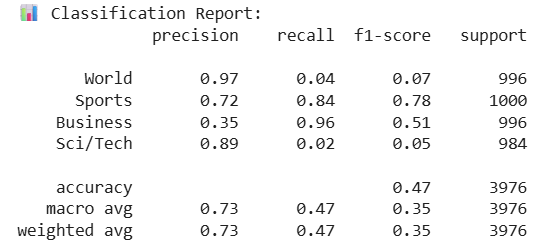

In [ ]:
from collections import Counter

wrong = val_results[val_results['qwen_pred'] != val_results['label']]
print("Which class have how many inaccurate predictions?")
print(Counter(wrong['label']))

Which class have how many inaccurate predictions?
Counter({0: 927, 3: 616, 2: 353, 1: 106})


In [ ]:
# hatalı tahminleri ayıklar
all_errors = val_results[val_results['label'] != val_results['qwen_pred']]

# her etiket için istendiği kadar hatalı örnek verir
# her etiketten 30 örnek incelenerek en sık hata yaptığı, etiketi ayırt edici kelimeler tespit edildi ve iyileştirmek için few-shot ile modele verildi
for label_id in sorted(val_results['label'].unique()):
    label_errors = all_errors[all_errors['label'] == label_id]

    if not label_errors.empty:
        print(f"\n---- Label {label_id} Misclassifications ({label_errors['label_name'].iloc[0]}) ----")
        for i, row in label_errors.head(3).iterrows():
            print("Headline:", row['text'])
            print(f"Actual Label: {row['label_name']} ({row['label']})")
            print(f"Qwen Prediction: {row['qwen_output']}  →  mapped to: {row['qwen_pred']}")
            print("-" * 80)


---- Label 0 Misclassifications (World) ----
Headline: Israeli Troops Kill 4 Palestinians in Gaza Raid  GAZA (Reuters) - Israeli troops killed four Palestinians,  including a militant and a 10-year-old girl, in northern Gaza  on Friday, bringing to 83 the Palestinian death toll from a  massive nine-day-old offensive.
Actual Label: World (0)
Qwen Prediction: Business  →  mapped to: 2
--------------------------------------------------------------------------------
Headline: Hurricane Ivan pounds US mainland Hurricane Ivan pummels the US Gulf Coast, causing at least 12 deaths and widespread damage. 
Actual Label: World (0)
Qwen Prediction: Business  →  mapped to: 2
--------------------------------------------------------------------------------
Headline: Blair denies he led Britain to war with false justification Prime Minister Tony Blair on Wednesday denied leading Britain into war on a false prospectus, despite intelligence on the threat posed by Iraq being wrong.
Actual Label: World (



---


**Daha detaylı prompt:** Haber alanları ve kapsamları hakkında bilgi verildi.

```
"You are a news article classifier. You must classify news headlines into one of these categories:
[World, Sports, Business, Sci/Tech]. Only respond with the category name.
Here is some information about the topics that may help:
1. **World** — News about international politics, government policies, diplomacy, law, conflicts, elections, or global social issues.
2. **Business** — News about companies, stock markets, investments, profits, economic trends, industries, or corporate strategy.
3. **Science/Technology** — News about new technology, inventions, software, hardware, science discoveries, space, or research.
4. **Sports** — News about sports teams, athletes, competitions, scores, matches, seasons, and sporting events."
```
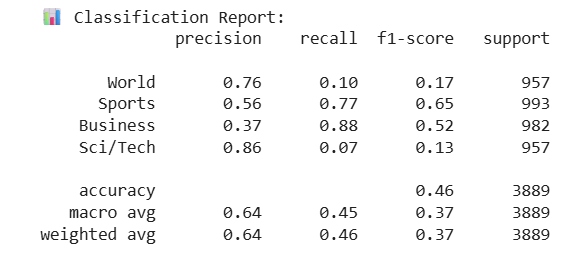






---


**Few shot prompt:** Hatalı tahmin edilen cümleler incelenip
içerdikleri kelimeler etiket ile beraber verildi.

```
You are a news article classifier. You must classify news headlines into one of these categories:
[World, Sports, Business, Sci/Tech]. Only respond with the category name.
 - World articles often include terms like: UN, Palestinian, Gaza, peace, election, Israel, minister, nuclear, president, Iraq, Iran, Afghanistan, rebel, asylum, intervention, Putin, Trump, veto.
 - Sports articles often include terms like: champion, score, cup, baseball, Olympic, win, sports, football, NHL, locker room, Formula One, Super Bowl, cricket.
 Anything Sports Network news agency reports should be labeled as Sports. Also if it has a branch of sports or a sports team name it is highly a sports article.
 - Business articles often include terms like: stock, supply, profit, economic, airlines, company, bank, inc, dollar, tax, billion, finance, economy, gas, oil, union, currency, export, merger, sales, market, trade, revenue, shareholder.
 - Sci/Tech articles often include terms like: Apple, music, technology, computer, Microsoft, software, scientist, Nasa, space, internet, engineering, gamer, Intel, theory, satellite, programming.
 If there is a game name like Scribe, Grand Theft Auto it is highly a sci/tech article. Also if it's an environmental issue or an animal species issue it may belong to Sci/Tech.
```
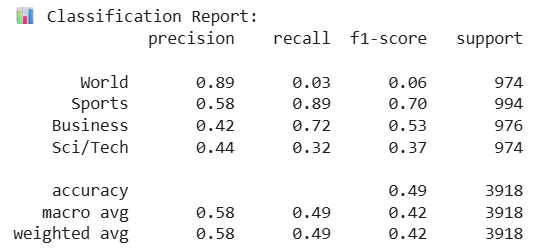




---


**Deneysel prompt:** Few shot için veri seti incelenirken mantıken Sci/Tech olmayacak ama diğer 3 etiket dışında kalan haberlerin de Sci/Tech'e eklendiği gözlemlendi. Bunun haricinde 2 etiketin arasında kalan, kesin bir ayrım yapılamayabilecek haberlerde modelin zorlandığı görüldü. Few shot'ın bu eksikliklerin daha sık görüldüğü Business ve Sci/Tech değerlerini iyileştirdiği görülürken World ve Sports'ta tam tersi yaşandı. Deneysel amaçlı etiketlerin yarısı için few shot uygulanarak denendi. Alınan en kötü sonuç elde edildi.
```
You are a news article classifier. You must classify news headlines into one of these categories: [World, Sports, Business, Sci/Tech]. Only respond with the category name.
 - Business articles often include terms like: stock, supply, profit, economic, airlines, company, bank, inc, dollar, tax, billion, finance, economy, gas, oil, union, currency, export, merger, sales, market, trade, revenue, shareholder.
 - Sci/Tech articles often include terms like: Apple, music, technology, computer, Microsoft, software, scientist, Nasa, space, internet, engineering, gamer, Intel, theory, satellite, programming. If there is a game name like Scribe, Grand Theft Auto it is highly a sci/tech article. Also if it's an environmental issue or an animal species issue it may belong to Sci/Tech.

```
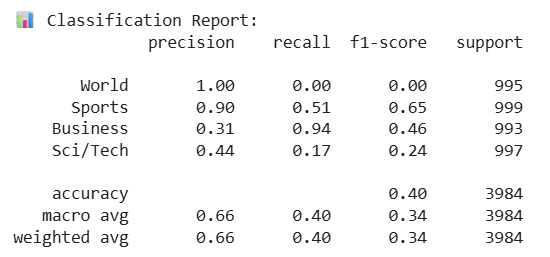




---


**2. Deneysel prompt:** Tüm etiketler için few shot eklendi ancak düşük f1 skorlular sadeleştirildi.
```
"You are a news article classifier. You must classify news headlines into one of these categories: [World, Sports, Business, Sci/Tech]. Only respond with the category name.
 - World articles often include terms like: UN, Palestinian, Gaza, peace, election, Israel, minister, president, Iraq, Iran, Afghanistan, Putin, Trump. News about international politics, government policies, diplomacy, law, conflicts, elections, or global social issues.
 - Sports articles often include terms like: champion, score, cup, baseball, Olympic, sports, football, NHL, cricket, Sports Network.
 - Business articles often include terms like: stock, supply, profit, economic, bank, inc, dollar, tax, finance, economy, gas, oil, union, currency, export, sales, market, trade, revenue.
 - Sci/Tech articles often include terms like: Apple, technology, computer, Microsoft, software, scientist, Nasa, space, internet, engineering, gamer, Intel, theory, satellite, programming. If there is a game name like Scribe, Grand Theft Auto it is highly a sci/tech article. Also if it's an environmental issue or an animal species issue it may belong to Sci/Tech."

```

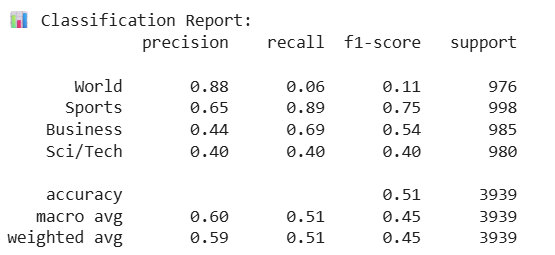



---


**F1-Score iyileştirmeli prompt:** World etiketi taşıyan verilerin recall değerinin çok düşük olduğu gözlemlendi. Model çoğunlukla World haberlerini Business haberleriyle karıştırdığından World etiketini seçme eşiği düşürülerek bunun düzeltilebileceği düşünüldü. Prompt olarak yönlendirme etkili olmadı, modelin weight'leri düzenlenerek başarılı sonuçlar elde edilebilir.
```
"You are a news article classifier. You must classify news headlines into one of these categories: [World, Sports, Business, Sci/Tech]. Only respond with the category name. Keep the treshold for World articles low because the precision is way higher than recall  for World.
 - World articles often include terms like: UN, Palestinian, Gaza, peace, election, Israel, minister, president, Iraq, Iran, Afghanistan, Putin, Trump. News about international politics, government policies, diplomacy, law, conflicts, elections, or global social issues.
 - Sports articles often include terms like: champion, score, cup, baseball, Olympic, sports, football, NHL, cricket, Sports Network.
 - Business articles often include terms like: stock, supply, profit, economic, bank, inc, dollar, tax, finance, economy, gas, oil, union, currency, export, sales, market, trade, revenue.
 - Sci/Tech articles often include terms like: Apple, technology, computer, Microsoft, software, scientist, Nasa, space, internet, engineering, gamer, Intel, theory, satellite, programming. If there is a game name like Scribe, Grand Theft Auto it is highly a sci/tech article. Also if it's an environmental issue or an animal species issue it may belong to Sci/Tech."

```
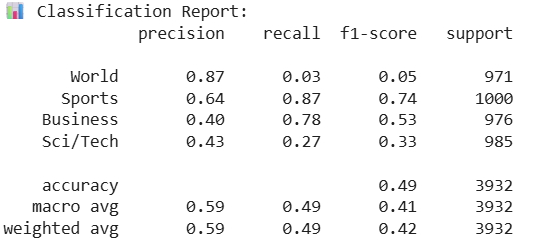

In conclusion, several factors are believed to contribute to the model's low accuracy:

*   Ambiguities in dataset labeling (overlap between World and Business news, unrelated Sci/Tech labels, and the need for domain knowledge or player names to interpret Sports news),
*   An inefficient threshold for classifying World news,

*   The model's training date (Qwen struggled with recent topics such as Israel’s genocide in Gaza, as our dataset primarily consists of news from the past year).
*   General model limitations (other LLMs demonstrate higher accuracy on similar tasks according to Hugging Face benchmarks),





In [ ]:
test_sample = pd.read_csv("/content/test.csv")
test_results = evaluate_dataset(test_sample)

# toplu bir csv oluşturma
logreg_df = pd.read_csv("/content/test_with_logreg.csv")  #dataset + logistic reg
merged_df = pd.merge(logreg_df, test_results[["text", "qwen_output", "qwen_pred"]], on="text", how="left")  #logreg ve qwen verilerini birleştirme
merged_df.to_csv("/content/test_with_logreg_and_qwen.csv", index=False) #save csv

100%|██████████| 7600/7600 [14:51<00:00,  8.52it/s]


 Accuracy: 0.4993

 Classification Report:
              precision    recall  f1-score   support

       World       0.84      0.07      0.13      1845
      Sports       0.64      0.89      0.75      1899
    Business       0.43      0.66      0.52      1880
    Sci/Tech       0.40      0.39      0.40      1871

    accuracy                           0.51      7495
   macro avg       0.58      0.50      0.45      7495
weighted avg       0.58      0.51      0.45      7495





---


**Fine-Tuning Qwen**

In [ ]:
from huggingface_hub import login
login()

In [ ]:
!pip install -q -U bitsandbytes
!pip install -q -U git+https://github.com/huggingface/transformers.git
!pip install -q -U git+https://github.com/huggingface/peft.git
!pip install -q -U git+https://github.com/huggingface/accelerate.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!pip install -q datasets

# peft -> Parameter-Efficient Fine-Tuning (contains methods like LoRa for efficient fine-tuning of large models)
# bitsandbytes -> Used for loading models in a quantized format (like 4-bit) to reduce memory usage

from datasets import load_dataset

ds = load_dataset("fancyzhx/ag_news")
id2label = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

from datasets import DatasetDict

full_train_data = ds["train"].shuffle(seed=42).select(range(500))
test_data = ds["test"].shuffle(seed=42).select(range(100))

split = full_train_data.train_test_split(test_size=0.2, seed=42)
train_data = split["train"]
val_data = split["test"]

In [ ]:
from huggingface_hub import HfApi, create_repo
from transformers import AutoTokenizer, AutoModelForCausalLM

# format the dataset into instruction-response pairs
def format_for_classification(example):
    prompt = f'Classify the following news headline into one of [World, Sports, Business, Sci/Tech]:\n"{example["text"]}"\nAnswer:'
    label = id2label[example["label"]]
    return {"prompt": prompt, "label_text": label}
#apply formatting
train_formatted = train_data.map(format_for_classification)
val_formatted = val_data.map(format_for_classification)
test_formatted = test_data.map(format_for_classification)
# load model and tokenizer


model_name = "Qwen/Qwen1.5-0.5B-Chat"

tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)

tokenizer.pad_token_id = tokenizer.eos_token_id #default to using the eos token as the padding token

import torch
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True
)

# configure lora
from peft import prepare_model_for_kbit_training, LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=16, # lora attention dimension
    lora_alpha=16,
    lora_dropout=0.1, #regularization için bazı nöronları devre dışı bırak
    bias="none",
    task_type="CAUSAL_LM", # Task type remains CAUSAL_LM for fine-tuning LLMs
    target_modules=["q_proj", "v_proj"] # lora hangi katmanları etkileyecek
)

model = get_peft_model(model, lora_config) # applies lora configuration to the original model


def tokenize_for_classification_ft(example):
    # Tokenize prompt and label separately
    prompt_enc = tokenizer(
        example["prompt"],
        truncation=True,
        max_length=256
    )
    label_enc = tokenizer(
        example["label_text"],
        truncation=True,
        max_length=10,
        add_special_tokens=False # Do not add special tokens to the label
    )

    # modelin girdi olarak alacağı token dizisi
    input_ids = prompt_enc["input_ids"] + label_enc["input_ids"] + [tokenizer.eos_token_id] # Add EOS token at the end

    # Create labels: -100 for prompt tokens, token_ids for label tokens
    labels = [-100] * len(prompt_enc["input_ids"]) + label_enc["input_ids"] + [tokenizer.eos_token_id] # Add EOS token label

    # Pad input_ids and labels
    max_length = 256 + 10 + 1 # Max prompt length + Max label length + EOS token
    padding_length = max_length - len(input_ids)
    input_ids = input_ids + [tokenizer.pad_token_id] * padding_length
    labels = labels + [-100] * padding_length # Pad labels with -100

    # Create attention mask
    attention_mask = [1] * (len(input_ids) - padding_length) + [0] * padding_length

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


train_tokenized = train_formatted.map(tokenize_for_classification_ft, batched=False)
val_tokenized = val_formatted.map(tokenize_for_classification_ft, batched=False)
test_tokenized = test_formatted.map(tokenize_for_classification_ft, batched=False)


# define training arguments
from transformers import TrainingArguments, Trainer, default_data_collator

training_args = TrainingArguments(
    output_dir="./qwen0.5b-classifier", # modelin log dosyalarını kaydedeceği yer
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    num_train_epochs=3,
    learning_rate=2e-5,
    logging_steps=10,
    save_steps=100,
    bf16=True,
    eval_strategy="epoch", # perform evaluation after each epoch
    report_to="none", #disable external logging
    warmup_ratio=0.05,
    gradient_checkpointing = False
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    data_collator=default_data_collator,
)

trainer.train()

# save fine-tuned model
model.save_pretrained("fine-tuned-qwen-0.5b")
tokenizer.save_pretrained("fine-tuned-qwen-0.5b")


Map:   0%|          | 0/100 [00:00<?, ? examples/s]

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Epoch,Training Loss,Validation Loss
1,0.446300,0.291818
2,0.255000,0.223635
3,0.099000,0.206958


('fine-tuned-qwen-0.5b/tokenizer_config.json',
 'fine-tuned-qwen-0.5b/special_tokens_map.json',
 'fine-tuned-qwen-0.5b/vocab.json',
 'fine-tuned-qwen-0.5b/merges.txt',
 'fine-tuned-qwen-0.5b/added_tokens.json',
 'fine-tuned-qwen-0.5b/tokenizer.json')

In [ ]:
repo_name = "qwen-1.5b-finetuned"
tokenizer.push_to_hub(repo_name)

In [ ]:
from sklearn.metrics import classification_report
import difflib
import torch

model_path = "fine-tuned-qwen-0.5b"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForCausalLM.from_pretrained(model_path, torch_dtype=torch.float16,device_map="auto")

# Etiket eşlemeleri
id2label = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
label2id = {v.lower(): k for k, v in id2label.items()}

# En yakın etiketi seçen fonksiyon (örneğin: "sci tech" → "sci/tech")
def normalize_label(output_text):
    output_text = output_text.lower().strip().replace("-", "").replace(" ", "")
    candidates = [label.lower().replace("/", "") for label in id2label.values()]
    match = difflib.get_close_matches(output_text, candidates, n=1, cutoff=0.5)
    if match:
        for label in id2label.values():
            if label.lower().replace("/", "") == match[0]:
                return label.lower()
    return "unknown"

# Değerlendirme
y_true = []
y_pred = []

for sample in test_formatted:
    prompt = f'Classify the following news headline into one of [World, Sports, Business, Sci/Tech]:\n"{sample["text"]}"\nAnswer:'
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    outputs = model.generate(**inputs, max_new_tokens=10, do_sample=False, top_p=None)
    decoded = tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True).strip()

    pred_label = normalize_label(decoded)
    true_label = id2label[sample["label"]].lower()

    if pred_label != "unknown":
        y_true.append(true_label)
        y_pred.append(pred_label)

print("Classification Report:\n")
print(classification_report(y_true, y_pred, digits=3))

for i, sample in enumerate(test_formatted.select(range(5))):
  prompt = f'Classify the following news headline into one of [World, Sports, Business, Sci/Tech]:\n"{sample["text"]}"\nAnswer:'
  inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
  outputs = model.generate(**inputs, max_new_tokens=10, do_sample=False, top_p=None)
  decoded = tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True).strip()

  pred_label = normalize_label(decoded)
  true_label = id2label[sample["label"]].lower()

  print(f"Headline: {sample['text']}")
  print(f"True Label: {true_label}")
  print(f"Qwen Prediction: {pred_label}")
  print("-" * 80)

Classification Report:

              precision    recall  f1-score   support

    business      0.697     0.719     0.708        32
    sci/tech      0.407     0.579     0.478        19
      sports      0.931     1.000     0.964        27
       world      1.000     0.500     0.667        22

    accuracy                          0.720       100
   macro avg      0.759     0.699     0.704       100
weighted avg      0.772     0.720     0.724       100

Headline: Indian board plans own telecast of Australia series The Indian cricket board said on Wednesday it was making arrangements on its own to broadcast next month #39;s test series against Australia, which is under threat because of a raging TV rights dispute.
True Label: sports
Qwen Prediction: sports
--------------------------------------------------------------------------------
Headline: Stocks Higher on Drop in Jobless Claims A sharp drop in initial unemployment claims and bullish forecasts from Nokia and Texas Instruments sen